<h1 align="center">E-Commerce Customer Segmentation</h1>
<h3 align="center"> Segment Playbook </h3>

**Project:** E-Commerce Customer Segmentation: RFM and K-Means Analysis of Who Drives, and Who Threatens, Revenue

This notebook answers **Objective 6** of the [analysis charter](../02_documentation/analysis_charter.md): *"Where should the next rupee of retention and marketing spend go?"*

It brings the results of NB03–NB05 together into one row per segment and one row per customer, and calculates every figure used in the written [segment playbook](../04_report/segment_playbook.md). It adds no new modelling.

**Why the charter's framework is revised.** The charter planned actions around "lapsing" and "coupon-dependent" customers. Testing showed that neither can be identified from past behaviour in this data: recency and the segments do not predict who stops buying *[NB04, Section 4]*, and coupon use is not a lasting customer trait *[NB05, Section 3]*. The playbook therefore uses each input only for what it was shown to do:

| Input | Used for | Evidence |
|---|---|---|
| Loyalty tier (× segment) | Lapse risk and priority | Best predictor of Jan–Jun 2026 lapse, AUC 0.606 *[NB04]* |
| K-means segment | What to offer and how to talk to the customer | Describes what and how customers buy *[NB03]* |
| Revenue | Value at stake | Where the money is |
| Recency | Not used as a trigger | No better than chance at predicting lapse *[NB04]* |

**Steps**

1. Load every customer's segment, scores, lists and flags.
2. Reproduce the NB04 lapse estimate for Jul–Dec 2026.
3. Assign each customer a playbook action.
4. Build one metrics row per segment (the playbook cards) and rank segments by value at stake.
5. Size the controlled trials the playbook recommends.
6. Save the scored customer file.

**Source tags.** Figures from earlier notebooks are tagged *[NB01]*–*[NB05]*. Every other figure is calculated here and is cited in the playbook as *[NB06]*.

| Input | Output |
|---|---|
| `01_data/output/customer_features_full.csv` *[NB01]* | `01_data/output/customer_segments.csv` |
| `01_data/output/rfm_scores_full.csv` *[NB02]*, `kmeans_segments_full.csv` *[NB03]* | `01_data/output/segment_playbook_metrics.csv` |
| `holdout_outcomes_calibration.csv`, `tier_upgrade_candidates.csv`, `platinum_low_activity.csv` *[NB04]* | `04_report/figures/nb06_value_at_stake.png` |
| `coupon_efficiency_by_segment.csv`, `cross_sell_targets.csv` *[NB05]*, `Fact_Sales.csv` | |

## 1. Load every customer's segment, scores and list memberships

In [1]:
# pathlib: build file paths that work on Windows, macOS and Linux
from pathlib import Path

# pandas: join the customer tables from earlier notebooks
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

OUTPUT_DIR = Path("../01_data/output")
SEGMENT_ORDER = ["Core high-value regulars", "Big-ticket Electronics buyers", "Coupon-led buyers",
                 "Frequent everyday shoppers", "Occasional light shoppers",
                 "Lapsed high-value customers", "Lapsed light buyers"]
TIER_ORDER = ["Silver", "Gold", "Platinum"]
FULL_MONTHS = 25

full = pd.read_csv(OUTPUT_DIR / "customer_features_full.csv", index_col="customer_id")
rfm = pd.read_csv(OUTPUT_DIR / "rfm_scores_full.csv", index_col="customer_id")
segments = pd.read_csv(OUTPUT_DIR / "kmeans_segments_full.csv", index_col="customer_id")
upgrade = pd.read_csv(OUTPUT_DIR / "tier_upgrade_candidates.csv", index_col="customer_id")
low_activity = pd.read_csv(OUTPUT_DIR / "platinum_low_activity.csv", index_col="customer_id")
winback = pd.read_csv(OUTPUT_DIR / "winback_ranked.csv", index_col="customer_id")
cross_sell = pd.read_csv(OUTPUT_DIR / "cross_sell_targets.csv", index_col="customer_id")

customers = full[full.frequency > 0][["customer_tier", "recency_days", "frequency", "aov", "monetary",
                                      "coupon_rate", "electronics_share", "category_breadth"]].copy()
customers = customers.join(segments[["kmeans_segment"]]).join(rfm[["r_score", "f_score", "m_score", "rfm_segment"]])
customers["kmeans_segment"] = pd.Categorical(customers.kmeans_segment, categories=SEGMENT_ORDER, ordered=True)
customers["customer_tier"] = pd.Categorical(customers.customer_tier, categories=TIER_ORDER, ordered=True)
customers["six_month_value"] = customers.monetary * 6 / FULL_MONTHS
customers["electronics_group"] = pd.cut(customers.electronics_share, bins=[-0.01, 0, 0.5, 1],
                                        labels=["Non-Electronics", "Mixed", "Electronics-led"])
customers["upgrade_trial"] = customers.index.isin(upgrade.index)
customers["platinum_low_activity"] = customers.index.isin(low_activity.index)
customers["winback_list"] = customers.index.isin(winback.index)
customers["cross_sell_target"] = customers.index.isin(cross_sell.index)
customers["next_category"] = cross_sell.next_category.reindex(customers.index)

print(f"Customers with valid orders: {len(customers):,} (not scored: {len(full) - len(customers)} with no completed purchase)")
for flag, expected in [("upgrade_trial", 1_858), ("platinum_low_activity", 4_058), ("winback_list", 8_054), ("cross_sell_target", 3_302)]:
    assert customers[flag].sum() == expected, flag
    print(f"  {flag:<22} {customers[flag].sum():>6,}")
assert customers[["kmeans_segment", "rfm_segment", "r_score"]].notna().all().all()

Customers with valid orders: 39,848 (not scored: 66 with no completed purchase)
  upgrade_trial           1,858
  platinum_low_activity   4,058
  winback_list            8,054
  cross_sell_target       3,302


## 2. Lapse estimate for Jul–Dec 2026

The same estimate as NB04, Section 8: each customer's expected lapse probability is the Jan–Jun 2026 lapse rate of calibration customers with the same **tier × K-means segment**. It is rebuilt here from NB04's saved outcomes, and the totals are checked against NB04.

In [2]:
outcomes = pd.read_csv(OUTPUT_DIR / "holdout_outcomes_calibration.csv", index_col="customer_id")
cell_rates = outcomes.groupby(["customer_tier", "kmeans_segment"]).lapsed.mean()
keys = pd.MultiIndex.from_arrays([customers.customer_tier.astype(str), customers.kmeans_segment.astype(str)])
customers["lapse_probability"] = cell_rates.reindex(keys).to_numpy()
customers["expected_revenue_at_risk"] = customers.lapse_probability * customers.six_month_value

print(f"Expected lapsers Jul–Dec 2026: {customers.lapse_probability.sum():,.0f} ({customers.lapse_probability.mean():.1%})")
print(f"Expected revenue at risk:      ₹{customers.expected_revenue_at_risk.sum() / 1e6:,.1f} M")
assert round(customers.expected_revenue_at_risk.sum() / 1e6, 1) == 261.2, "Differs from NB04, Section 8"

Expected lapsers Jul–Dec 2026: 8,991 (22.6%)
Expected revenue at risk:      ₹261.2 M


## 3. Assign each customer a playbook action

Every customer gets one **primary action** from their K-means segment. Three **overlays** are flagged separately, because they apply to customers across segments.

| Primary action | Segments | Reason |
|---|---|---|
| **Protect** | Core high-value regulars, Big-ticket Electronics buyers, Coupon-led buyers | Most of the revenue and of the expected revenue at risk. Coupon-led buyers are included because their coupon habit did not last *[NB05, Section 3]* |
| **Light-touch contact** | Lapsed high-value customers | High past value, but quiet customers came back without intervention *[NB04, Section 7]*, so no costly win-back |
| **Low-cost automated** | Frequent everyday shoppers, Occasional light shoppers | Low value per customer |
| **Deprioritise** | Lapsed light buyers | 0.4% of revenue *[NB03]* |

| Overlay | Customers | Source |
|---|---|---|
| **Cross-sell trial** (Sports first) | Electronics-led customers with room to add a category | *[NB05, Section 10]* |
| **Upgrade trial** | Silver and Gold customers in top-value segments | *[NB04, Section 7]* |
| **Platinum contact trial** | Low-activity Platinum customers | *[NB04, Section 7]* |

The coupon recommendation (cap `SAVE10`) applies to every segment and is a pricing rule, not a customer action *[NB05, Section 5]*.

In [3]:
ACTION = {
    "Core high-value regulars": "Protect",
    "Big-ticket Electronics buyers": "Protect",
    "Coupon-led buyers": "Protect",
    "Frequent everyday shoppers": "Low-cost automated",
    "Occasional light shoppers": "Low-cost automated",
    "Lapsed high-value customers": "Light-touch contact",
    "Lapsed light buyers": "Deprioritise",
}
ACTION_ORDER = ["Protect", "Light-touch contact", "Low-cost automated", "Deprioritise"]
customers["playbook_action"] = pd.Categorical(customers.kmeans_segment.astype(str).map(ACTION), categories=ACTION_ORDER, ordered=True)

by_action = customers.groupby("playbook_action", observed=True).agg(
    customers=("monetary", "size"), revenue=("monetary", "sum"), six_month_value=("six_month_value", "sum"),
    expected_revenue_at_risk=("expected_revenue_at_risk", "sum"), cross_sell_targets=("cross_sell_target", "sum"),
    upgrade_trial=("upgrade_trial", "sum"), platinum_low_activity=("platinum_low_activity", "sum"))
by_action.insert(1, "share_of_customers", by_action.customers / by_action.customers.sum())
by_action.insert(3, "share_of_revenue", by_action.revenue / by_action.revenue.sum())
by_action.insert(6, "share_of_risk", by_action.expected_revenue_at_risk / by_action.expected_revenue_at_risk.sum())
M = lambda v: f"₹{v / 1e6:,.1f} M"
by_action.style.format({"customers": "{:,.0f}", "share_of_customers": "{:.1%}", "revenue": M, "share_of_revenue": "{:.1%}",
                        "six_month_value": M, "expected_revenue_at_risk": M, "share_of_risk": "{:.1%}",
                        "cross_sell_targets": "{:,.0f}", "upgrade_trial": "{:,.0f}", "platinum_low_activity": "{:,.0f}"})

,customers,share_of_customers,revenue,share_of_revenue,six_month_value,expected_revenue_at_risk,share_of_risk,cross_sell_targets,upgrade_trial,platinum_low_activity
playbook_action,,,,,,,,,,
Protect,"21,824",54.8%,"₹4,226.3 M",79.3%,"₹1,014.3 M",₹208.0 M,79.6%,"3,020","1,858","1,357"
Light-touch contact,"3,177",8.0%,₹378.0 M,7.1%,₹90.7 M,₹19.5 M,7.5%,269,0,"2,356"
Low-cost automated,"12,848",32.2%,₹701.6 M,13.2%,₹168.4 M,₹32.3 M,12.4%,0,0,320
Deprioritise,"1,999",5.0%,₹22.2 M,0.4%,₹5.3 M,₹1.3 M,0.5%,13,0,25


**Findings:**

- **Protect covers 21,824 customers (54.8%)**, who hold 79.3% of revenue and 79.6% of the expected revenue at risk in Jul–Dec 2026 (₹208.0 M of ₹261.2 M).
- **Low-cost automated covers 12,848 customers (32.2%)**, with 13.2% of revenue and ₹32.3 M at risk.
- **Light-touch contact covers 3,177 customers (8.0%)** with ₹19.5 M at risk. 2,356 of them are also on the low-activity Platinum list.
- **Deprioritise covers 1,999 customers (5.0%)** with only ₹1.3 M at risk.
- **The overlays sit mostly inside Protect:**
  - 3,020 of the 3,302 cross-sell targets;
  - all 1,858 upgrade-trial customers;
  - 1,357 of the 4,058 low-activity Platinum customers.

## 4. Segment cards

One row per segment with every field of the charter's playbook card:

| Card field | Columns | Source |
|---|---|---|
| Size and share of revenue | customers, revenue, shares, six-month value | *[NB03]* |
| Behaviour summary | median recency, frequency, AOV, Electronics share of revenue | *[NB03]*, *[NB05]* |
| Tier mix and mismatch | Platinum share, upgrade-trial and low-activity Platinum counts | *[NB04]* |
| Lapse risk and ₹ at risk | Jan–Jun 2026 lapse rate of the calibration segment; expected lapse rate and ₹ at risk for Jul–Dec 2026 | *[NB04]* |
| Coupon response | coupon discounts, cost rate, order-value gap, and the six-month saving from a ₹1,000 cap on `SAVE10` | *[NB05]* |
| Cross-sell potential | targets and revenue at 10% take-up | *[NB05]* |

The `SAVE10` cap saving is recalculated by segment here (NB05 gave it for the whole business): the discount above ₹1,000 on each `SAVE10` order, over 25 months, scaled to six months.

In [4]:
# customer_features.py (this folder): shared order-status rules, used to read the valid orders for the coupon saving
import customer_features as cf

fact, _, _ = cf.load_data("../01_data/processed")
save10 = fact[fact.order_status.isin(cf.VALID_STATUSES) & (fact.coupon_code == "SAVE10")].join(
    customers[["kmeans_segment"]], on="customer_id")
cap_saving = ((save10.coupon_discount - 1_000).clip(lower=0).groupby(save10.kmeans_segment, observed=True).sum()
              * 6 / FULL_MONTHS)
print(f"Six-month saving from a ₹1,000 SAVE10 cap, all segments: ₹{cap_saving.sum() / 1e6:,.2f} M "
      f"(NB05: ₹40.56 M over 25 months = ₹{40.56 * 6 / 25:,.2f} M per six months)")

valid = fact[fact.order_status.isin(cf.VALID_STATUSES)].join(customers[["kmeans_segment"]], on="customer_id")
electronics_share_of_revenue = (valid[valid.category == "Electronics"].groupby("kmeans_segment", observed=True).total_amount.sum()
                                / valid.groupby("kmeans_segment", observed=True).total_amount.sum())

Six-month saving from a ₹1,000 SAVE10 cap, all segments: ₹9.73 M (NB05: ₹40.56 M over 25 months = ₹9.73 M per six months)


In [5]:
coupons = pd.read_csv(OUTPUT_DIR / "coupon_efficiency_by_segment.csv", index_col="kmeans_segment")
outcomes["kmeans_segment"] = pd.Categorical(outcomes.kmeans_segment, categories=SEGMENT_ORDER, ordered=True)

g = customers.groupby("kmeans_segment", observed=True)
cards = pd.DataFrame({
    "action": pd.Series(ACTION),
    "customers": g.size(),
    "revenue": g.monetary.sum(),
    "six_month_value": g.six_month_value.sum(),
    "median_recency_days": g.recency_days.median(),
    "median_frequency": g.frequency.median(),
    "median_aov": g.aov.median(),
    "electronics_share_of_revenue": electronics_share_of_revenue,
    "platinum_share": g.customer_tier.apply(lambda t: (t == "Platinum").mean()),
    "upgrade_trial": g.upgrade_trial.sum(),
    "platinum_low_activity": g.platinum_low_activity.sum(),
    "lapse_rate_jan_jun_2026": outcomes.groupby("kmeans_segment", observed=True).lapsed.mean(),
    "expected_lapse_rate": g.lapse_probability.mean(),
    "expected_revenue_at_risk": g.expected_revenue_at_risk.sum(),
    "coupon_discount_25_months": coupons.discount,
    "coupon_cost_rate": coupons.coupon_cost_rate,
    "coupon_order_value_gap": coupons.order_value_gap,
    "save10_cap_saving_six_months": cap_saving,
    "cross_sell_targets": g.cross_sell_target.sum(),
}).reindex(SEGMENT_ORDER)
cards.index.name = "kmeans_segment"
cross_sell_value = cross_sell.groupby("kmeans_segment").next_category_aov.sum() * 0.10
cards["cross_sell_revenue_at_10pct"] = cross_sell_value.reindex(SEGMENT_ORDER).fillna(0)
cards.insert(2, "share_of_customers", cards.customers / cards.customers.sum())
cards.insert(4, "share_of_revenue", cards.revenue / cards.revenue.sum())
cards.insert(cards.columns.get_loc("expected_revenue_at_risk") + 1, "share_of_risk",
             cards.expected_revenue_at_risk / cards.expected_revenue_at_risk.sum())
cards = cards.sort_values("expected_revenue_at_risk", ascending=False)
cards.insert(0, "priority", range(1, len(cards) + 1))

CARD_FORMAT = {"customers": "{:,.0f}", "share_of_customers": "{:.1%}", "revenue": M, "share_of_revenue": "{:.1%}",
               "six_month_value": M, "median_recency_days": "{:,.0f}", "median_frequency": "{:,.0f}", "median_aov": "₹{:,.0f}",
               "electronics_share_of_revenue": "{:.1%}", "platinum_share": "{:.1%}", "upgrade_trial": "{:,.0f}",
               "platinum_low_activity": "{:,.0f}", "lapse_rate_jan_jun_2026": "{:.1%}", "expected_lapse_rate": "{:.1%}",
               "expected_revenue_at_risk": M, "share_of_risk": "{:.1%}", "coupon_discount_25_months": lambda v: f"₹{v / 1e6:,.2f} M",
               "coupon_cost_rate": "{:.2%}", "coupon_order_value_gap": "{:+.1%}",
               "save10_cap_saving_six_months": lambda v: f"₹{v / 1e6:,.2f} M", "cross_sell_targets": "{:,.0f}",
               "cross_sell_revenue_at_10pct": lambda v: f"₹{v / 1e6:,.2f} M"}

# Display the cards transposed (one column per segment), each row formatted by its own rule
display_cards = cards.copy().astype(object)
for col, fmt in CARD_FORMAT.items():
    display_cards[col] = cards[col].map(fmt if callable(fmt) else fmt.format)
display_cards.T

kmeans_segment,Core high-value regulars,Big-ticket Electronics buyers,Coupon-led buyers,Frequent everyday shoppers,Lapsed high-value customers,Occasional light shoppers,Lapsed light buyers
priority,1,2,3,4,5,6,7
action,Protect,Protect,Protect,Low-cost automated,Light-touch contact,Low-cost automated,Deprioritise
customers,"11,130","5,068","5,626","6,806","3,177","6,042","1,999"
share_of_customers,27.9%,12.7%,14.1%,17.1%,8.0%,15.2%,5.0%
revenue,"₹2,377.7 M",₹941.7 M,₹906.9 M,₹449.0 M,₹378.0 M,₹252.6 M,₹22.2 M
share_of_revenue,44.6%,17.7%,17.0%,8.4%,7.1%,4.7%,0.4%
six_month_value,₹570.7 M,₹226.0 M,₹217.7 M,₹107.8 M,₹90.7 M,₹60.6 M,₹5.3 M
median_recency_days,58,93,76,67,328,75,284
median_frequency,7,4,6,7,4,4,2
median_aov,"₹27,834","₹40,339","₹23,846","₹8,658","₹25,204","₹7,968","₹3,118"


### Tier breakdown within each segment

Expected revenue at risk for Jul–Dec 2026 by segment and tier.

In [6]:
risk_by_tier = customers.pivot_table(index="kmeans_segment", columns="customer_tier", values="expected_revenue_at_risk",
                                     aggfunc="sum", observed=False).reindex(SEGMENT_ORDER)[TIER_ORDER]
count_by_tier = pd.crosstab(customers.kmeans_segment, customers.customer_tier).reindex(SEGMENT_ORDER)[TIER_ORDER]
display((risk_by_tier / 1e6).style.format("₹{:,.1f} M"))
display(count_by_tier.style.format("{:,.0f}"))

customer_tier,Silver,Gold,Platinum
kmeans_segment,,,
Core high-value regulars,₹1.1 M,₹3.2 M,₹126.3 M
Big-ticket Electronics buyers,₹1.3 M,₹1.9 M,₹47.9 M
Coupon-led buyers,₹0.9 M,₹2.2 M,₹23.3 M
Frequent everyday shoppers,₹2.2 M,₹6.1 M,₹13.0 M
Occasional light shoppers,₹3.0 M,₹4.5 M,₹3.5 M
Lapsed high-value customers,₹1.3 M,₹2.6 M,₹15.6 M
Lapsed light buyers,₹0.9 M,₹0.3 M,₹0.0 M


customer_tier,Silver,Gold,Platinum
kmeans_segment,,,
Core high-value regulars,100,416,"10,614"
Big-ticket Electronics buyers,201,357,"4,510"
Coupon-led buyers,174,610,"4,842"
Frequent everyday shoppers,"1,095","2,368","3,343"
Occasional light shoppers,"2,338","2,045","1,659"
Lapsed high-value customers,222,599,"2,356"
Lapsed light buyers,"1,677",297,25


### Value at stake

Segments ranked by expected revenue at risk in Jul–Dec 2026, shown against their six-month value.

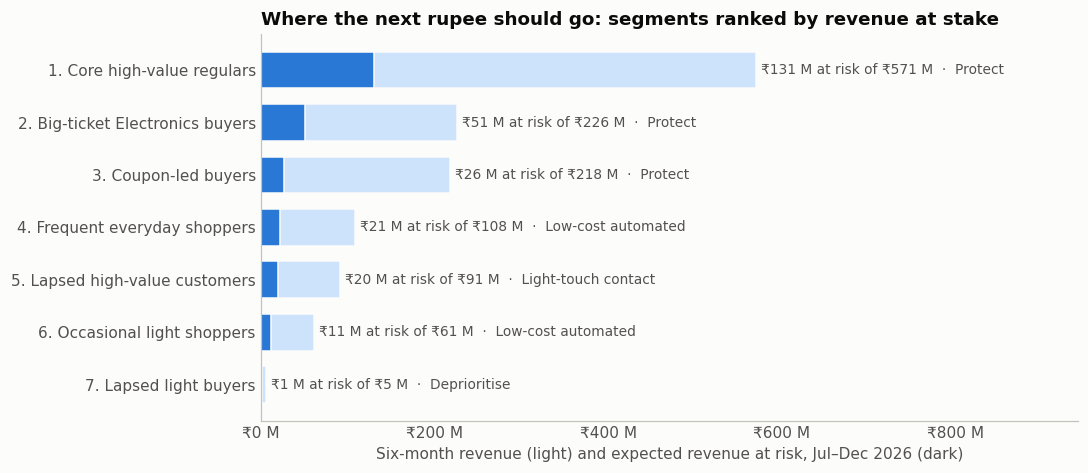

In [7]:
# matplotlib: draw the chart; FuncFormatter formats axis numbers
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# plot_style.py (this folder): shared colours and chart defaults for every notebook
import plot_style as ps
ps.apply()

plot = cards[::-1]
fig, ax = plt.subplots(figsize=(10, 4.4))
y = range(len(plot))
ax.barh(y, plot.six_month_value / 1e6, height=0.7, color=ps.BLUE_RAMP[0], edgecolor=ps.SURFACE, linewidth=1)
ax.barh(y, plot.expected_revenue_at_risk / 1e6, height=0.7, color=ps.SERIES[0], edgecolor=ps.SURFACE, linewidth=1)
for i, (value, risk, action) in enumerate(zip(plot.six_month_value / 1e6, plot.expected_revenue_at_risk / 1e6, plot.action)):
    ax.text(value + 6, i, f"₹{risk:,.0f} M at risk of ₹{value:,.0f} M  ·  {action}", va="center", fontsize=9,
            color=ps.TEXT_SECONDARY)
ax.set_yticks(list(y), [f"{p}. {s}" for p, s in zip(plot.priority, plot.index)])
ax.set_xlim(0, plot.six_month_value.max() / 1e6 * 1.65)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"₹{v:,.0f} M"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Six-month revenue (light) and expected revenue at risk, Jul–Dec 2026 (dark)")
ax.set_title("Where the next rupee should go: segments ranked by revenue at stake", loc="left")
fig.tight_layout()
ps.save(fig, "nb06_value_at_stake")
plt.show()

**Findings:**

- **Priority order by expected revenue at risk:**
  1. Core high-value regulars: ₹130.5 M, 50.0%
  2. Big-ticket Electronics buyers: ₹51.1 M, 19.6%
  3. Coupon-led buyers: ₹26.4 M, 10.1%
  4. Frequent everyday shoppers: ₹21.2 M
  5. Lapsed high-value customers: ₹19.5 M
  6. Occasional light shoppers: ₹11.1 M
  7. Lapsed light buyers: ₹1.3 M
- **The first three segments hold 79.6% of the value at stake**, almost all of it from Platinum customers (₹197.5 M of ₹208.0 M).
- **Risk follows value, not lapse rate.** In Jan–Jun 2026, every segment lapsed at 22.1%–23.7% *[NB04]*. The ranking comes from where the money is.
- **Coupon-led buyers have the lowest expected lapse rate (13.5%).** This is because many are Platinum customers in a tier × segment group that lapsed rarely in 2026, not because coupons retain them *[NB05, Section 4]*.
- **A ₹1,000 cap on `SAVE10` saves about ₹9.7 M per six months.** Most of the saving comes from Coupon-led buyers (₹3.50 M), Core high-value regulars (₹3.09 M) and Big-ticket Electronics buyers (₹1.74 M).
- **Cross-sell potential is concentrated in Big-ticket Electronics buyers:** 2,927 of the 3,302 targets and ₹3.63 M of the ₹4.09 M at 10% take-up.

## 5. Sizing the controlled trials

Every action in the playbook is recommended as a **controlled trial**: half of the eligible customers receive the treatment and half do not, and the two halves are compared after six months. Before running a trial, the business should know the smallest effect it could reliably detect.

The **minimum detectable effect** below is the smallest difference in six-month lapse rate between the two halves that the trial would detect with 80% power at the 5% significance level, using the standard two-proportion formula:

$$ MDE = (z_{0.975} + z_{0.80}) \sqrt{p(1-p)\left(\frac{1}{n_1} + \frac{1}{n_2}\right)} $$

where *p* is the baseline rate of the trial's KPI (the group's expected lapse rate, or for the cross-sell trial the natural rate at which these customers add Sports) and *n₁*, *n₂* are the two halves.

In [8]:
# numpy and scipy.stats.norm: the normal-distribution values in the formula
import numpy as np
from scipy.stats import norm

Z = norm.ppf(0.975) + norm.ppf(0.80)
SPORTS_ADD_RATE = 0.161  # Electronics-led customers with room who added Sports in Jan–Jun 2026 [NB05, Section 8]
protect = customers.playbook_action == "Protect"
trials = [
    # (trial, eligible customers, KPI, baseline rate of the KPI)
    ("Protect: Platinum customers", protect & (customers.customer_tier == "Platinum"), "Six-month lapse rate", None),
    ("SAVE10 cap", pd.Series(True, index=customers.index), "Six-month lapse rate", None),
    ("Cross-sell (Sports first)", customers.cross_sell_target, "Share adding the suggested category", SPORTS_ADD_RATE),
    ("Upgrade trial", customers.upgrade_trial, "Six-month lapse rate", None),
    ("Platinum contact trial", customers.platinum_low_activity, "Six-month lapse rate", None),
    ("Light-touch contact (Lapsed high-value)", customers.playbook_action == "Light-touch contact", "Six-month lapse rate", None),
]
rows = []
for name, mask, kpi, baseline in trials:
    n = int(mask.sum())
    p = baseline if baseline is not None else customers.loc[mask, "lapse_probability"].mean()
    rows.append({"trial": name, "kpi": kpi, "eligible_customers": n, "per_arm": n // 2, "baseline_rate": p,
                 "minimum_detectable_effect": Z * np.sqrt(p * (1 - p) * (2 / (n // 2)))})
trial_table = pd.DataFrame(rows).set_index("trial")
trial_table.style.format({"eligible_customers": "{:,.0f}", "per_arm": "{:,.0f}", "baseline_rate": "{:.1%}",
                          "minimum_detectable_effect": lambda v: f"{v * 100:.1f} percentage points"})

,kpi,eligible_customers,per_arm,baseline_rate,minimum_detectable_effect
trial,,,,,
Protect: Platinum customers,Six-month lapse rate,"19,966","9,983",19.7%,1.6 percentage points
SAVE10 cap,Six-month lapse rate,"39,848","19,924",22.6%,1.2 percentage points
Cross-sell (Sports first),Share adding the suggested category,"3,302","1,651",16.1%,3.6 percentage points
Upgrade trial,Six-month lapse rate,"1,858",929,32.5%,6.1 percentage points
Platinum contact trial,Six-month lapse rate,"4,058","2,029",18.8%,3.4 percentage points
Light-touch contact (Lapsed high-value),Six-month lapse rate,"3,177","1,588",24.1%,4.2 percentage points


**Findings:**

- **The large trials can detect small effects.** A `SAVE10` cap across all customers could detect a change in lapse rate of 1.2 percentage points. A Protect trial on Platinum customers could detect 1.6 points.
- **The list-based trials can only detect moderate effects:**
  - Platinum contact: 3.4 points;
  - cross-sell: 3.6 points on a 16.1% natural Sports add rate;
  - light-touch contact: 4.2 points;
  - upgrade trial: 6.1 points.

  If the true effect is smaller than this, the trial will probably miss it.
- **The upgrade trial is the weakest test.** With 1,858 eligible customers it can only detect a 6-point change. It should run alongside the larger trials, not replace them.

In each trial, one half of the eligible customers receives the treatment and the other half, the **control group**, does not. Without a control group, none of these actions could be shown to work. NB04 found that quiet Platinum customers returned and that customers add categories without any campaign.

## 6. Save the outputs

| File | Contents |
|---|---|
| `customer_segments.csv` | One row per customer with valid orders: tier, K-means and RFM segments, RFM scores, recency, frequency, AOV, spend, Electronics group, expected lapse probability and revenue at risk, playbook action, list flags and suggested next category. This is the file marketing would load into a CRM |
| `segment_playbook_metrics.csv` | The segment cards in Section 4 |

In [9]:
COLUMNS = ["customer_tier", "kmeans_segment", "rfm_segment", "r_score", "f_score", "m_score", "recency_days", "frequency",
           "aov", "monetary", "electronics_group", "lapse_probability", "expected_revenue_at_risk", "playbook_action",
           "winback_list", "upgrade_trial", "platinum_low_activity", "cross_sell_target", "next_category"]
customers[COLUMNS].sort_values("expected_revenue_at_risk", ascending=False).to_csv(OUTPUT_DIR / "customer_segments.csv")
cards.to_csv(OUTPUT_DIR / "segment_playbook_metrics.csv")
for f in ["customer_segments.csv", "segment_playbook_metrics.csv"]:
    print(f"Saved 01_data/output/{f}  ({(OUTPUT_DIR / f).stat().st_size / 1e3:,.0f} KB)")

Saved 01_data/output/customer_segments.csv  (7,155 KB)
Saved 01_data/output/segment_playbook_metrics.csv  (3 KB)


## 7. Summary

| Question | Answer *[NB06]* |
|---|---|
| Where is the value at stake? | ₹261.2 M expected revenue at risk in Jul–Dec 2026. 79.6% of it is in the three Protect segments, almost all Platinum |
| What is the order of priority? | 1. Core high-value regulars, 2. Big-ticket Electronics buyers, 3. Coupon-led buyers, 4. Frequent everyday shoppers, 5. Lapsed high-value customers, 6. Occasional light shoppers, 7. Lapsed light buyers |
| What does each segment get? | Protect (segments 1–3), Low-cost automated (4 and 6), Light-touch contact (5), Deprioritise (7), with cross-sell, upgrade and Platinum contact trials as overlays |
| Where can cost be cut? | A ₹1,000 `SAVE10` cap saves about ₹9.7 M per six months |
| How will we know it works? | Every action runs as a controlled trial. The large trials can detect a 1–2 point change in lapse rate; the list-based trials, 3–6 points |

The written playbook, [`04_report/segment_playbook.md`](../04_report/segment_playbook.md), turns these figures into one card per segment. The scored customer file, `customer_segments.csv`, carries each customer's action and list flags for use in a CRM.